In [1]:
import torch
import os
import numpy as np

# ============================================================
# 1. Check PyTorch and CUDA
# ============================================================

print("=" * 60)
print("PyTorch / GPU Setup")
print("=" * 60)

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

# ============================================================
# 2. Automatically select GPU with the most FREE VRAM
# ============================================================

if torch.cuda.is_available():

    num_gpus = torch.cuda.device_count()
    print(f"GPU count       : {num_gpus}")

    best_gpu_idx = None
    max_free_mem = -1

    print("\nAvailable GPUs:")
    print("-" * 60)

    for i in range(num_gpus):

        try:
            # Get free and total VRAM
            free_mem, total_mem = torch.cuda.mem_get_info(i)

            free_gb = free_mem / (1024 ** 3)
            total_gb = total_mem / (1024 ** 3)

            gpu_name = torch.cuda.get_device_name(i)

            print(
                f"GPU {i}: {gpu_name} | "
                f"Free: {free_gb:.2f} GB / {total_gb:.2f} GB"
            )

            # Select GPU with maximum free VRAM
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i

        except Exception as e:
            print(f"GPU {i}: Could not check memory - {e}")

    # ========================================================
    # 3. Select the GPU
    # ========================================================

    if best_gpu_idx is not None:

        device = torch.device(f"cuda:{best_gpu_idx}")

        # Make this GPU the current CUDA device
        torch.cuda.set_device(best_gpu_idx)

        # Clear unused cached memory
        torch.cuda.empty_cache()

        selected_gpu_name = torch.cuda.get_device_name(best_gpu_idx)

        print("\n" + "=" * 60)
        print("SELECTED GPU")
        print("=" * 60)

        print(f"GPU index       : {best_gpu_idx}")
        print(f"GPU name        : {selected_gpu_name}")
        print(f"Free VRAM       : {max_free_mem / (1024 ** 3):.2f} GB")
        print(f"Device          : {device}")

    else:
        device = torch.device("cpu")
        print("\nCould not select a GPU. Using CPU.")

else:

    device = torch.device("cpu")

    print("\n" + "=" * 60)
    print("NO CUDA GPU AVAILABLE")
    print("=" * 60)

    print("Using CPU.")

# ============================================================
# 4. Set random seeds
# ============================================================

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# 5. Final information
# ============================================================

print("\n" + "=" * 60)
print("SETUP COMPLETE ✓")
print("=" * 60)

print(f"Selected device : {device}")
print(f"Random seed     : {SEED}")

PyTorch / GPU Setup
PyTorch version : 2.8.0+cu128
CUDA available  : True
GPU count       : 8

Available GPUs:
------------------------------------------------------------
GPU 0: NVIDIA A100-SXM4-80GB | Free: 4.23 GB / 79.15 GB
GPU 1: NVIDIA A100-SXM4-80GB | Free: 1.49 GB / 79.15 GB
GPU 2: NVIDIA A100-SXM4-80GB | Free: 20.63 GB / 79.15 GB
GPU 3: NVIDIA A100-SXM4-80GB | Free: 67.80 GB / 79.15 GB
GPU 4: NVIDIA A100-SXM4-80GB | Free: 29.74 GB / 79.15 GB
GPU 5: NVIDIA A100-SXM4-80GB | Free: 31.08 GB / 79.15 GB
GPU 6: NVIDIA A100-SXM4-80GB | Free: 62.15 GB / 79.15 GB
GPU 7: NVIDIA A100-SXM4-80GB | Free: 33.46 GB / 79.15 GB

SELECTED GPU
GPU index       : 3
GPU name        : NVIDIA A100-SXM4-80GB
Free VRAM       : 67.80 GB
Device          : cuda:3

SETUP COMPLETE ✓
Selected device : cuda:3
Random seed     : 42


NETCDF DATASET INFORMATION
<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): time(2048), traces(70637), comp(3), side(128)
    variables(dimensions): float32 chunk(traces, comp, time), int64 class(traces), float32 distance(traces), int64 seis(traces), int64 image(traces, side, side, comp)
    groups: class_dict

DIMENSIONS
time                 : 2048
traces               : 70637
comp                 : 3
side                 : 128

VARIABLES

Variable: chunk
  Data type : float32
  Shape     : (70637, 3, 2048)
  Dimensions: ('traces', 'comp', 'time')

Variable: class
  Data type : int64
  Shape     : (70637,)
  Dimensions: ('traces',)

Variable: distance
  Data type : float32
  Shape     : (70637,)
  Dimensions: ('traces',)

Variable: seis
  Data type : int64
  Shape     : (70637,)
  Dimensions: ('traces',)

Variable: image
  Data type : int64
  Shape     : (70637, 128, 128, 3)
  Dimensions: ('traces', 'side', 'side', 'comp')

SAMPLE DAT

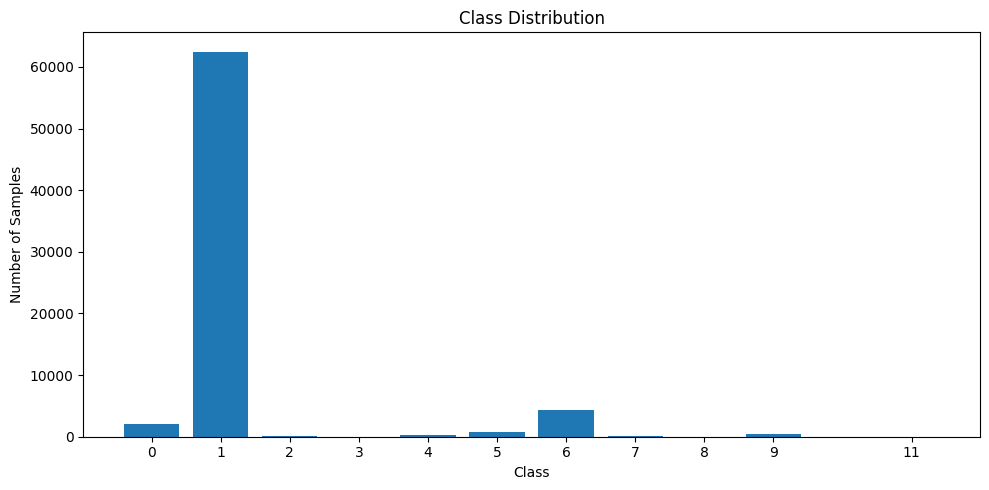


DATASET INSPECTION COMPLETE ✓


In [3]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Open the NetCDF file
# ============================================================

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

print("=" * 70)
print("NETCDF DATASET INFORMATION")
print("=" * 70)

print(dataset)


# ============================================================
# 2. Show dimensions
# ============================================================

print("\n" + "=" * 70)
print("DIMENSIONS")
print("=" * 70)

for name, dimension in dataset.dimensions.items():
    print(f"{name:20s} : {len(dimension)}")


# ============================================================
# 3. Show all variables
# ============================================================

print("\n" + "=" * 70)
print("VARIABLES")
print("=" * 70)

for name, variable in dataset.variables.items():

    print(f"\nVariable: {name}")
    print(f"  Data type : {variable.dtype}")
    print(f"  Shape     : {variable.shape}")
    print(f"  Dimensions: {variable.dimensions}")

    # Show attributes
    if variable.ncattrs():
        print("  Attributes:")

        for attr in variable.ncattrs():
            print(f"    {attr}: {getattr(variable, attr)}")


# ============================================================
# 4. Show sample data
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE DATA")
print("=" * 70)

for name, variable in dataset.variables.items():

    print(f"\n--- {name} ---")

    try:
        data = variable[:]

        print(f"Shape     : {data.shape}")
        print(f"Data type : {data.dtype}")

        if data.ndim == 0:

            print("Value:")
            print(data)

        elif data.ndim == 1:

            print("First 10 values:")
            print(data[:10])

        else:

            print("First sample:")
            print(data[0])

    except Exception as e:

        print(f"Could not read data: {e}")


# ============================================================
# 5. Numerical statistics
# ============================================================

print("\n" + "=" * 70)
print("NUMERICAL STATISTICS")
print("=" * 70)

for name, variable in dataset.variables.items():

    try:

        data = variable[:]

        # Only numerical variables
        if not np.issubdtype(data.dtype, np.number):
            continue

        data_float = np.asarray(data, dtype=float)

        print(f"\n{name}")

        print(f"  Shape : {data.shape}")
        print(f"  Min   : {np.nanmin(data_float):.6f}")
        print(f"  Max   : {np.nanmax(data_float):.6f}")
        print(f"  Mean  : {np.nanmean(data_float):.6f}")
        print(f"  Std   : {np.nanstd(data_float):.6f}")

    except Exception as e:

        print(f"{name}: statistics unavailable ({e})")


# ============================================================
# 6. Class / label distribution
# ============================================================

if 'class' in dataset.variables:

    print("\n" + "=" * 70)
    print("CLASS / LABEL DISTRIBUTION")
    print("=" * 70)

    labels = dataset['class'][:].astype(int)

    unique_classes, class_counts = np.unique(
        labels,
        return_counts=True
    )

    print(f"Total samples: {len(labels)}")

    for cls, count in zip(unique_classes, class_counts):

        percentage = count / len(labels) * 100

        print(
            f"Class {cls:3d}: "
            f"{count:6d} samples "
            f"({percentage:.2f}%)"
        )


    # ========================================================
    # Plot class distribution
    # ========================================================

    plt.figure(figsize=(10, 5))

    plt.bar(
        unique_classes,
        class_counts
    )

    plt.xlabel("Class")
    plt.ylabel("Number of Samples")
    plt.title("Class Distribution")

    plt.xticks(unique_classes)

    plt.tight_layout()
    plt.show()


# ============================================================
# 7. Close dataset
# ============================================================

dataset.close()

print("\n" + "=" * 70)
print("DATASET INSPECTION COMPLETE ✓")
print("=" * 70)

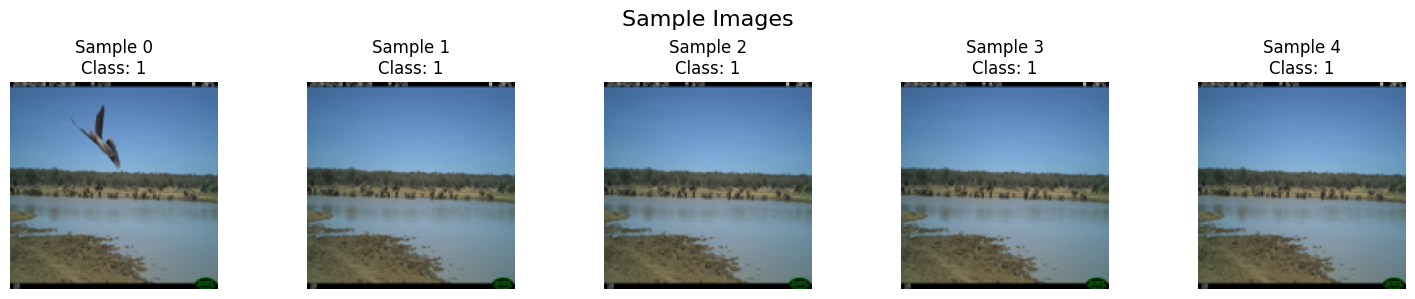

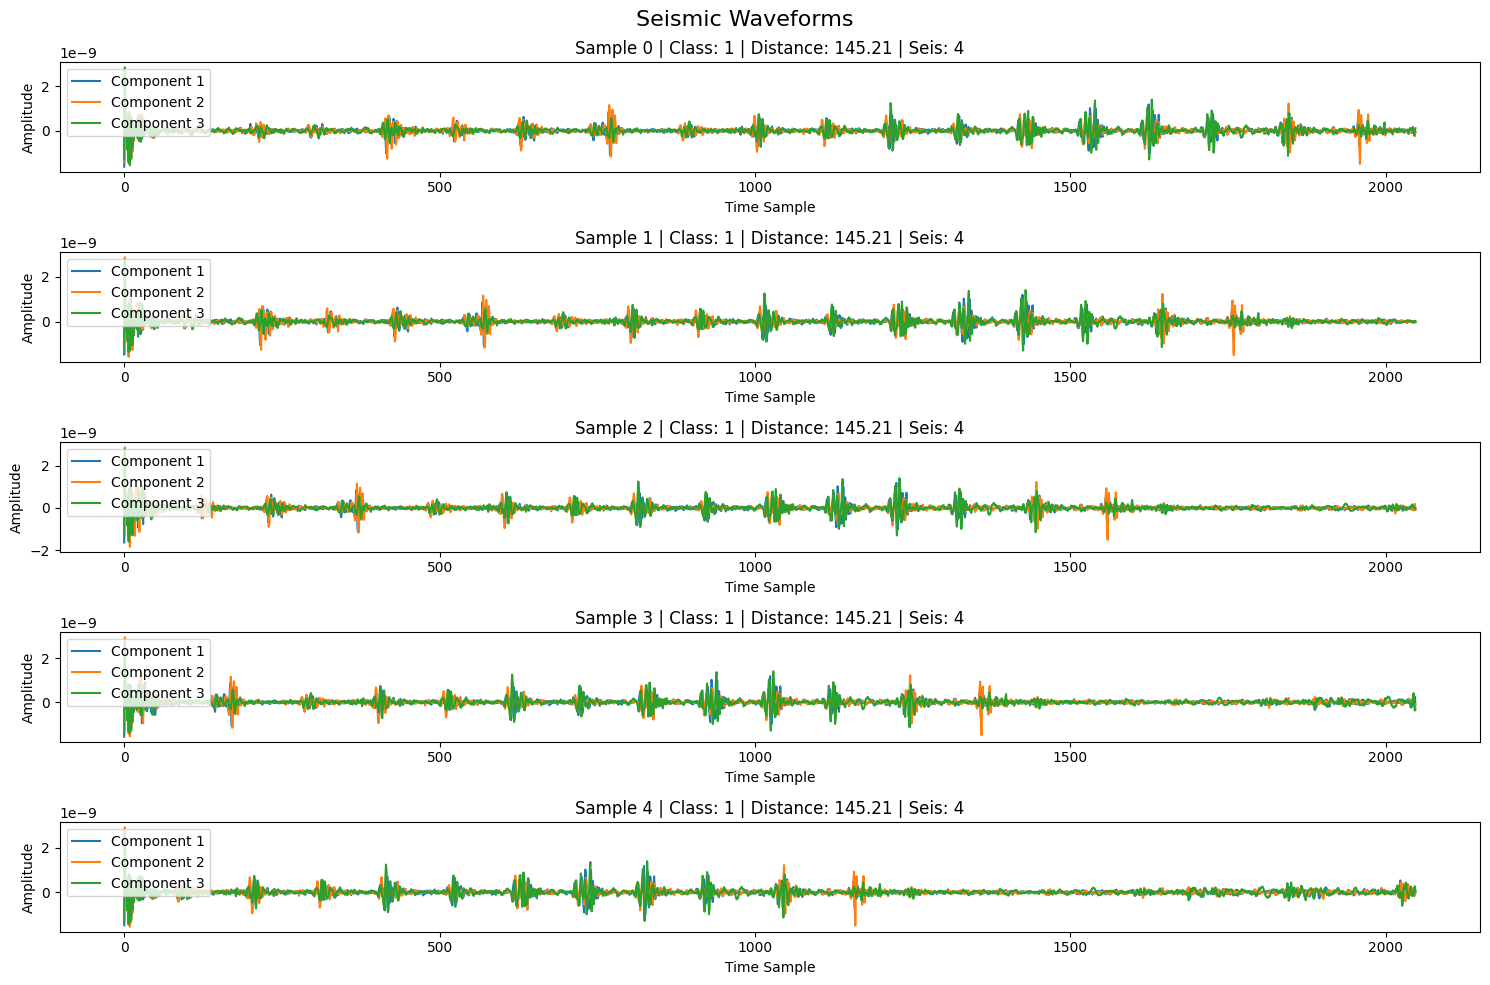

In [4]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Open dataset
# ============================================================

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

# Number of samples to display
NUM_SAMPLES = 5

# Select sample indices
sample_indices = [0, 1, 2, 3, 4]

# ============================================================
# Plot images
# ============================================================

plt.figure(figsize=(15, 3))

for i, idx in enumerate(sample_indices):

    image = dataset['image'][idx]

    plt.subplot(1, NUM_SAMPLES, i + 1)

    plt.imshow(image)
    plt.title(f"Sample {idx}\nClass: {dataset['class'][idx]}")

    plt.axis('off')

plt.suptitle("Sample Images", fontsize=16)

plt.tight_layout()
plt.show()


# ============================================================
# Plot seismic waveforms
# ============================================================

plt.figure(figsize=(15, 10))

for i, idx in enumerate(sample_indices):

    # Get seismic data
    waveform = dataset['chunk'][idx]

    # waveform shape = (3, 2048)

    plt.subplot(NUM_SAMPLES, 1, i + 1)

    # Plot all 3 components
    plt.plot(waveform[0], label='Component 1')
    plt.plot(waveform[1], label='Component 2')
    plt.plot(waveform[2], label='Component 3')

    plt.title(
        f"Sample {idx} | "
        f"Class: {dataset['class'][idx]} | "
        f"Distance: {dataset['distance'][idx]:.2f} | "
        f"Seis: {dataset['seis'][idx]}"
    )

    plt.xlabel("Time Sample")
    plt.ylabel("Amplitude")
    plt.legend()

plt.suptitle("Seismic Waveforms", fontsize=16)

plt.tight_layout()
plt.show()


# ============================================================
# Close dataset
# ============================================================

dataset.close()

Classes found: [ 0  1  2  3  4  5  6  7  8  9 11]
Class 0: Selected sample 64133
Class 1: Selected sample 40844
Class 2: Selected sample 66194
Class 3: Selected sample 69968
Class 4: Selected sample 65957
Class 5: Selected sample 4609
Class 6: Selected sample 14446
Class 7: Selected sample 35336
Class 8: Selected sample 46299
Class 9: Selected sample 60172
Class 11: Selected sample 65144


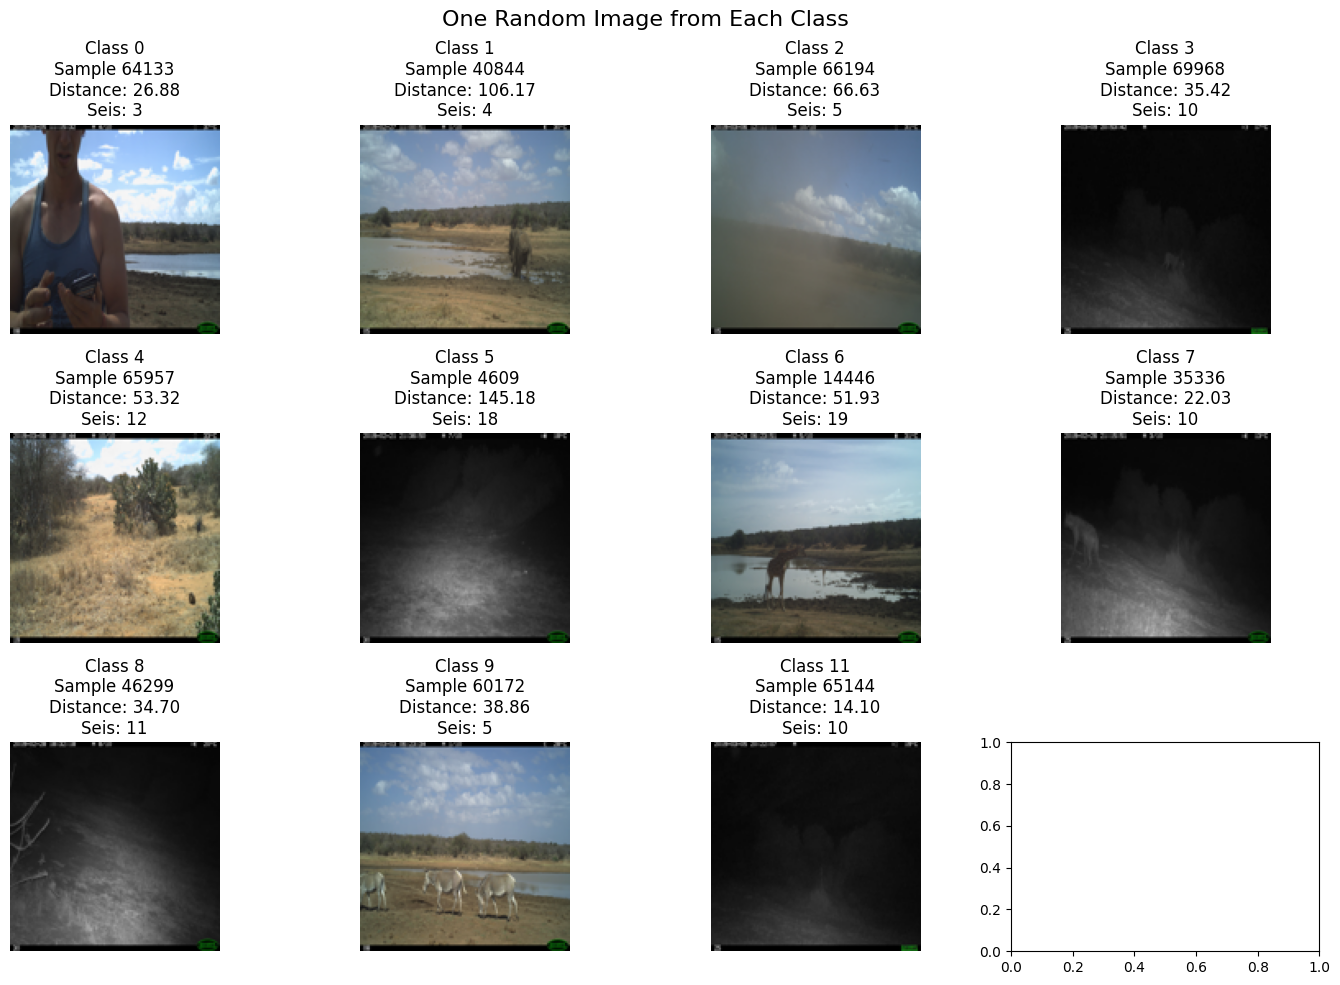

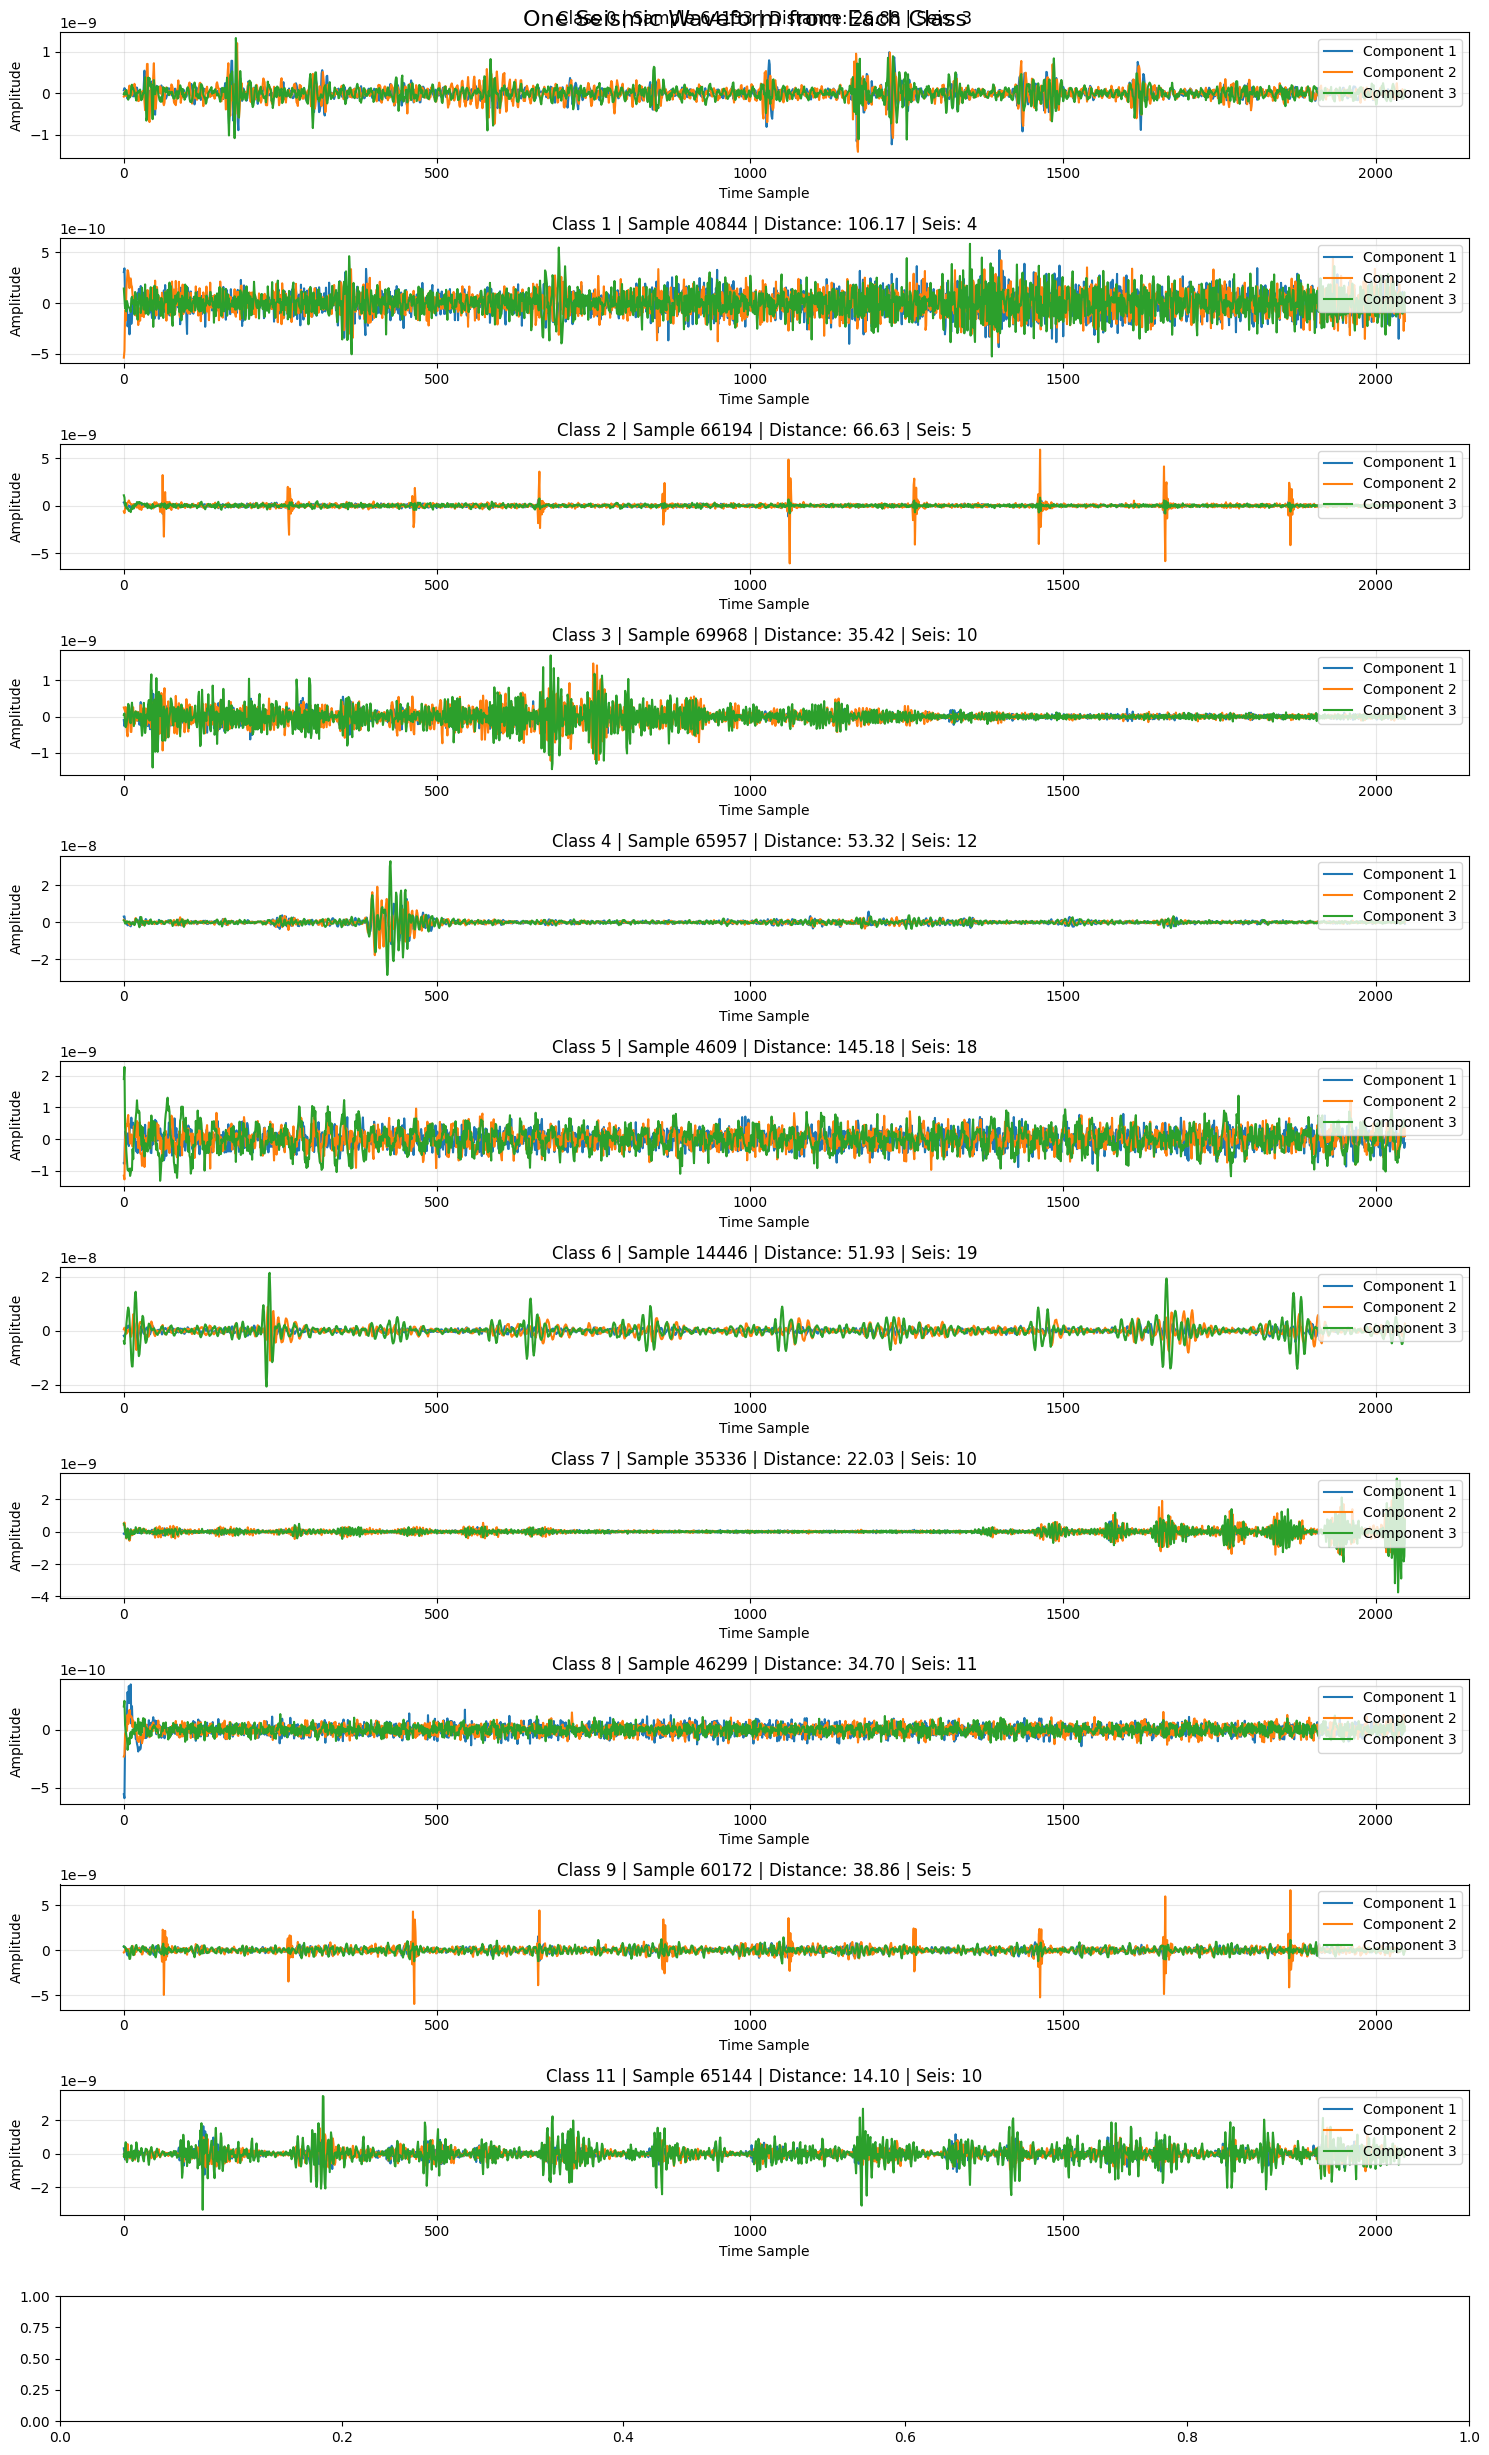

In [5]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Open dataset
# ============================================================

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

# Read labels
labels = dataset['class'][:].astype(int)

# Find all classes
unique_classes = np.unique(labels)

print("Classes found:", unique_classes)


# ============================================================
# 2. Find ONE RANDOM sample from each class
# ============================================================

np.random.seed(42)

selected_samples = []

for cls in unique_classes:

    # Find indices belonging to this class
    class_indices = np.where(labels == cls)[0]

    # Pick one random sample
    random_index = np.random.choice(class_indices)

    selected_samples.append(random_index)

    print(
        f"Class {cls}: "
        f"Selected sample {random_index}"
    )


# ============================================================
# 3. Display images
# ============================================================

fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

axes = axes.flatten()

for i, idx in enumerate(selected_samples):

    image = dataset['image'][idx]

    cls = int(dataset['class'][idx])
    distance = float(dataset['distance'][idx])
    seis = int(dataset['seis'][idx])

    axes[i].imshow(image)

    axes[i].set_title(
        f"Class {cls}\n"
        f"Sample {idx}\n"
        f"Distance: {distance:.2f}\n"
        f"Seis: {seis}"
    )

    axes[i].axis('off')


plt.suptitle(
    "One Random Image from Each Class",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. Display seismic waveforms
# ============================================================

fig, axes = plt.subplots(
    12, 1,
    figsize=(15, 25)
)

for i, idx in enumerate(selected_samples):

    waveform = dataset['chunk'][idx]

    cls = int(dataset['class'][idx])
    distance = float(dataset['distance'][idx])
    seis = int(dataset['seis'][idx])

    # Component 1
    axes[i].plot(
        waveform[0],
        label='Component 1'
    )

    # Component 2
    axes[i].plot(
        waveform[1],
        label='Component 2'
    )

    # Component 3
    axes[i].plot(
        waveform[2],
        label='Component 3'
    )

    axes[i].set_title(
        f"Class {cls} | "
        f"Sample {idx} | "
        f"Distance: {distance:.2f} | "
        f"Seis: {seis}"
    )

    axes[i].set_xlabel("Time Sample")
    axes[i].set_ylabel("Amplitude")

    axes[i].legend(
        loc='upper right'
    )

    axes[i].grid(True, alpha=0.3)


plt.suptitle(
    "One Seismic Waveform from Each Class",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. Close dataset
# ============================================================

dataset.close()

In [6]:
import netCDF4 as nc

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

print("=" * 70)
print("CLASS DICTIONARY")
print("=" * 70)

# Check groups
print("\nGroups found:")
print(list(dataset.groups.keys()))

# Access class_dict
if 'class_dict' in dataset.groups:

    class_dict = dataset.groups['class_dict']

    print("\n" + "=" * 70)
    print("class_dict INFORMATION")
    print("=" * 70)

    print(class_dict)

    # Show dimensions
    print("\nDimensions:")
    for name, dim in class_dict.dimensions.items():
        print(f"  {name}: {len(dim)}")

    # Show variables
    print("\nVariables:")
    if len(class_dict.variables) == 0:
        print("  No variables found.")

    for name, variable in class_dict.variables.items():

        print(f"\n  Variable: {name}")
        print(f"    Shape : {variable.shape}")
        print(f"    Type  : {variable.dtype}")

        try:
            print(f"    Data  : {variable[:]}")
        except Exception as e:
            print(f"    Could not read data: {e}")

        # Variable attributes
        if variable.ncattrs():
            print("    Attributes:")
            for attr in variable.ncattrs():
                print(
                    f"      {attr}: "
                    f"{getattr(variable, attr)}"
                )

    # Show group attributes
    print("\nGroup attributes:")

    if class_dict.ncattrs():

        for attr in class_dict.ncattrs():
            print(
                f"  {attr}: "
                f"{getattr(class_dict, attr)}"
            )

    else:
        print("  No group attributes found.")

else:
    print("\nclass_dict group was not found.")

dataset.close()

CLASS DICTIONARY

Groups found:
['class_dict']

class_dict INFORMATION
<class 'netCDF4.Group'>
group /class_dict:
    HOMINIDAE: 0
    ELEPHANTIDAE: 1
    SUIDAE: 2
    FELIDAE: 3
    NUMIDIDAE: 4
    BOVIDAE: 5
    GIRAFFIDAE: 6
    HYAENIDAE: 7
    LEPORIDAE: 8
    EQUIDAE: 9
    MUSTELIDAE: 10
    HIPPOPOTAMIDAE: 11
    dimensions(sizes): 
    variables(dimensions): 
    groups: 

Dimensions:

Variables:
  No variables found.

Group attributes:
  HOMINIDAE: 0
  ELEPHANTIDAE: 1
  SUIDAE: 2
  FELIDAE: 3
  NUMIDIDAE: 4
  BOVIDAE: 5
  GIRAFFIDAE: 6
  HYAENIDAE: 7
  LEPORIDAE: 8
  EQUIDAE: 9
  MUSTELIDAE: 10
  HIPPOPOTAMIDAE: 11


In [7]:
import netCDF4 as nc
import numpy as np

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

# Class ID → Family name
class_names = {
    0: 'HOMINIDAE',
    1: 'ELEPHANTIDAE',
    2: 'SUIDAE',
    3: 'FELIDAE',
    4: 'NUMIDIDAE',
    5: 'BOVIDAE',
    6: 'GIRAFFIDAE',
    7: 'HYAENIDAE',
    8: 'LEPORIDAE',
    9: 'EQUIDAE',
    10: 'MUSTELIDAE',
    11: 'HIPPOPOTAMIDAE'
}

# Read labels
labels = dataset['class'][:].astype(int)

# Count samples
unique_classes, class_counts = np.unique(
    labels,
    return_counts=True
)

print("=" * 70)
print("ANIMAL CLASS DISTRIBUTION")
print("=" * 70)

print(f"Total samples : {len(labels)}")
print(f"Total classes : {len(unique_classes)}")
print()

for cls, count in zip(unique_classes, class_counts):

    percentage = count / len(labels) * 100

    print(
        f"Class {cls:2d} | "
        f"{class_names[cls]:15s} | "
        f"{count:6d} samples | "
        f"{percentage:6.2f}%"
    )

dataset.close()

ANIMAL CLASS DISTRIBUTION
Total samples : 70637
Total classes : 11

Class  0 | HOMINIDAE       |   2073 samples |   2.93%
Class  1 | ELEPHANTIDAE    |  62493 samples |  88.47%
Class  2 | SUIDAE          |    164 samples |   0.23%
Class  3 | FELIDAE         |      2 samples |   0.00%
Class  4 | NUMIDIDAE       |    271 samples |   0.38%
Class  5 | BOVIDAE         |    769 samples |   1.09%
Class  6 | GIRAFFIDAE      |   4321 samples |   6.12%
Class  7 | HYAENIDAE       |     42 samples |   0.06%
Class  8 | LEPORIDAE       |     10 samples |   0.01%
Class  9 | EQUIDAE         |    488 samples |   0.69%
Class 11 | HIPPOPOTAMIDAE  |      4 samples |   0.01%


In [8]:
import netCDF4 as nc
import numpy as np

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

seis = dataset['seis'][:].astype(int)
labels = dataset['class'][:].astype(int)

unique_seis, seis_counts = np.unique(
    seis,
    return_counts=True
)

print("=" * 60)
print("SEIS DISTRIBUTION")
print("=" * 60)

print(f"Number of unique seis values: {len(unique_seis)}")
print()

for s, count in zip(unique_seis, seis_counts):

    # Classes associated with this seis value
    classes_for_seis = np.unique(labels[seis == s])

    print(
        f"Seis {s:2d} : "
        f"{count:6d} traces | "
        f"Classes: {classes_for_seis}"
    )

dataset.close()

SEIS DISTRIBUTION
Number of unique seis values: 10

Seis  3 :  13951 traces | Classes: [0 1 2 4 5 6 9]
Seis  4 :  13617 traces | Classes: [0 1 2 4 5 6 9]
Seis  5 :  10542 traces | Classes: [0 1 2 4 5 6 9]
Seis 10 :    872 traces | Classes: [ 0  1  3  4  5  6  7  9 11]
Seis 11 :   9130 traces | Classes: [0 1 2 4 5 6 8 9]
Seis 12 :   1881 traces | Classes: [0 1 4 5 6 7 9]
Seis 16 :    393 traces | Classes: [0 1 5 6 9]
Seis 17 :   6306 traces | Classes: [0 1 2 4 5 6 9]
Seis 18 :   8486 traces | Classes: [0 1 2 4 5 6 9]
Seis 19 :   5459 traces | Classes: [0 1 2 4 5 6 9]


In [9]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

chunk = dataset['chunk']

print("=" * 60)
print("SEISMIC SIGNAL INFORMATION")
print("=" * 60)

print("Shape:", chunk.shape)
print("Data type:", chunk.dtype)

# Read a small portion first
sample = chunk[0]

print("One sample shape:", sample.shape)

print("\nNumber of components:", sample.shape[0])
print("Number of time samples:", sample.shape[1])

print("\nMinimum amplitude:", np.min(sample))
print("Maximum amplitude:", np.max(sample))
print("Mean amplitude:", np.mean(sample))
print("Standard deviation:", np.std(sample))

dataset.close()

SEISMIC SIGNAL INFORMATION
Shape: (70637, 3, 2048)
Data type: float32
One sample shape: (3, 2048)

Number of components: 3
Number of time samples: 2048

Minimum amplitude: -1.6250599e-09
Maximum amplitude: 2.8606875e-09
Mean amplitude: -2.9420148e-14
Standard deviation: 2.0322327e-10


In [10]:
import netCDF4 as nc
import numpy as np

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')
chunk = dataset['chunk']

# Number of samples to inspect
num_samples = chunk.shape[0]

# Take every 100th trace
indices = np.arange(0, num_samples, 100)

mins = []
maxs = []
means = []
stds = []

for idx in indices:
    signal = chunk[idx]

    mins.append(np.min(signal))
    maxs.append(np.max(signal))
    means.append(np.mean(signal))
    stds.append(np.std(signal))

mins = np.array(mins)
maxs = np.array(maxs)
means = np.array(means)
stds = np.array(stds)

print("=" * 60)
print("DATASET-WIDE SIGNAL STATISTICS")
print("=" * 60)

print("Traces inspected:", len(indices))

print("\nMinimum amplitude:")
print("  Smallest:", np.min(mins))
print("  Largest :", np.max(mins))

print("\nMaximum amplitude:")
print("  Smallest:", np.min(maxs))
print("  Largest :", np.max(maxs))

print("\nMean:")
print("  Minimum:", np.min(means))
print("  Maximum:", np.max(means))

print("\nStandard deviation:")
print("  Minimum:", np.min(stds))
print("  Maximum:", np.max(stds))
print("  Average:", np.mean(stds))

dataset.close()

DATASET-WIDE SIGNAL STATISTICS
Traces inspected: 707

Minimum amplitude:
  Smallest: -2.1036142e-07
  Largest : -1.481751e-10

Maximum amplitude:
  Smallest: 1.658827e-10
  Largest : 2.752322e-07

Mean:
  Minimum: -2.6021364e-11
  Maximum: 1.0295615e-11

Standard deviation:
  Minimum: 3.417557e-11
  Maximum: 2.1800533e-08
  Average: 1.0417189e-09


In [11]:
import netCDF4 as nc
import numpy as np

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')
chunk = dataset['chunk']

# Inspect every 100th trace
indices = np.arange(0, chunk.shape[0], 100)

component_stats = []

for idx in indices:
    signal = chunk[idx]   # shape: (3, 2048)

    for c in range(3):
        component_stats.append([
            c,
            np.mean(signal[c]),
            np.std(signal[c]),
            np.min(signal[c]),
            np.max(signal[c])
        ])

component_stats = np.array(component_stats)

print("=" * 70)
print("COMPONENT-WISE SEISMIC STATISTICS")
print("=" * 70)

for c in range(3):

    data = component_stats[component_stats[:, 0] == c]

    print(f"\nComponent {c + 1}")
    print("-" * 40)

    print(f"Mean of means : {np.mean(data[:, 1]):.4e}")
    print(f"Average std   : {np.mean(data[:, 2]):.4e}")
    print(f"Minimum value : {np.min(data[:, 3]):.4e}")
    print(f"Maximum value : {np.max(data[:, 4]):.4e}")

dataset.close()

COMPONENT-WISE SEISMIC STATISTICS

Component 1
----------------------------------------
Mean of means : -1.0196e-14
Average std   : 6.8387e-10
Minimum value : -2.0109e-07
Maximum value : 1.6515e-07

Component 2
----------------------------------------
Mean of means : -1.8419e-14
Average std   : 1.1292e-09
Minimum value : -1.7322e-07
Maximum value : 1.3784e-07

Component 3
----------------------------------------
Mean of means : -1.5648e-13
Average std   : 1.1909e-09
Minimum value : -2.1036e-07
Maximum value : 2.7523e-07


In [12]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

# Select one trace
idx = 0

signal = dataset['chunk'][idx].astype(np.float32)

# Normalize each component separately
normalized = np.zeros_like(signal)

for c in range(3):
    mean = np.mean(signal[c])
    std = np.std(signal[c])

    normalized[c] = (signal[c] - mean) / (std + 1e-12)

# Print statistics
print("=" * 60)
print("NORMALIZATION CHECK")
print("=" * 60)

for c in range(3):
    print(f"\nComponent {c + 1}")
    print(f"Original mean : {np.mean(signal[c]):.4e}")
    print(f"Original std  : {np.std(signal[c]):.4e}")
    print(f"New mean      : {np.mean(normalized[c]):.4f}")
    print(f"New std       : {np.std(normalized[c]):.4f}")

dataset.close()

NORMALIZATION CHECK

Component 1
Original mean : -6.9209e-14
Original std  : 1.9593e-10
New mean      : 0.0000
New std       : 0.9949

Component 2
Original mean : -4.4290e-14
Original std  : 2.0338e-10
New mean      : 0.0000
New std       : 0.9951

Component 3
Original mean : 2.5239e-14
Original std  : 2.1012e-10
New mean      : -0.0000
New std       : 0.9953


In [13]:
import netCDF4 as nc
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

chunk = dataset['chunk']
labels = dataset['class'][:].astype(int)

# Take 1000 traces for testing
N = 1000

signals = chunk[:N].astype(np.float32)
y = labels[:N]

dataset.close()

print("=" * 60)
print("SMALL GRAPH / SIMILARITY TEST")
print("=" * 60)

print("Signals shape:", signals.shape)
print("Labels shape :", y.shape)

# --------------------------------------------------
# Normalize each trace/component
# --------------------------------------------------

normalized = np.zeros_like(signals)

for i in range(N):
    for c in range(3):

        mean = np.mean(signals[i, c])
        std = np.std(signals[i, c])

        normalized[i, c] = (
            signals[i, c] - mean
        ) / (std + 1e-12)

print("Normalized shape:", normalized.shape)

# --------------------------------------------------
# Flatten each trace
# --------------------------------------------------

features = normalized.reshape(N, -1)

print("Feature shape:", features.shape)

# --------------------------------------------------
# Calculate similarity between traces
# --------------------------------------------------

similarity = cosine_similarity(features)

print("Similarity matrix shape:", similarity.shape)

# --------------------------------------------------
# Check one example
# --------------------------------------------------

sample_idx = 0

similarities = similarity[sample_idx].copy()

# Ignore itself
similarities[sample_idx] = -1

# Get 5 most similar traces
nearest = np.argsort(similarities)[-5:][::-1]

print("\nTrace", sample_idx, "class:", y[sample_idx])

print("\n5 most similar traces:")

for idx in nearest:
    print(
        f"Trace {idx:4d} | "
        f"Similarity: {similarity[sample_idx, idx]:.4f} | "
        f"Class: {y[idx]}"
    )

SMALL GRAPH / SIMILARITY TEST
Signals shape: (1000, 3, 2048)
Labels shape : (1000,)
Normalized shape: (1000, 3, 2048)
Feature shape: (1000, 6144)
Similarity matrix shape: (1000, 1000)

Trace 0 class: 1

5 most similar traces:
Trace    9 | Similarity: 0.3457 | Class: 1
Trace    8 | Similarity: 0.3224 | Class: 1
Trace    6 | Similarity: 0.2891 | Class: 1
Trace    7 | Similarity: 0.2859 | Class: 1
Trace    2 | Similarity: 0.2766 | Class: 1


In [14]:
import netCDF4 as nc
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

N = 1000

signals = dataset['chunk'][:N].astype(np.float32)
labels = dataset['class'][:N].astype(int)

dataset.close()

# --------------------------------------------------
# Normalize each trace
# --------------------------------------------------

normalized = np.zeros_like(signals)

for i in range(N):
    for c in range(3):
        mean = np.mean(signals[i, c])
        std = np.std(signals[i, c])

        normalized[i, c] = (
            signals[i, c] - mean
        ) / (std + 1e-12)

# --------------------------------------------------
# Flatten
# --------------------------------------------------

features = normalized.reshape(N, -1)

# --------------------------------------------------
# Similarity
# --------------------------------------------------

similarity = cosine_similarity(features)

# --------------------------------------------------
# Check nearest neighbors for different classes
# --------------------------------------------------

classes_to_check = [0, 1, 2, 4, 5, 6, 9]

print("=" * 70)
print("NEAREST-NEIGHBOR CLASS CONSISTENCY")
print("=" * 70)

for target_class in classes_to_check:

    # Find traces belonging to this class
    class_indices = np.where(labels == target_class)[0]

    if len(class_indices) == 0:
        continue

    # Pick the first trace from this class
    sample_idx = class_indices[0]

    similarities = similarity[sample_idx].copy()

    # Ignore itself
    similarities[sample_idx] = -1

    # Find 5 nearest neighbors
    nearest = np.argsort(similarities)[-5:][::-1]

    neighbor_classes = labels[nearest]

    same_class = np.sum(neighbor_classes == target_class)

    print(f"\nTarget Class: {target_class}")
    print(f"Trace selected: {sample_idx}")

    print("Neighbor classes:", neighbor_classes)

    print(
        f"Same-class neighbors: "
        f"{same_class}/5"
    )

NEAREST-NEIGHBOR CLASS CONSISTENCY

Target Class: 1
Trace selected: 0
Neighbor classes: [1 1 1 1 1]
Same-class neighbors: 5/5

Target Class: 9
Trace selected: 122
Neighbor classes: [9 1 1 1 1]
Same-class neighbors: 1/5


In [15]:
import netCDF4 as nc
import numpy as np
from sklearn.model_selection import train_test_split

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

dataset = nc.Dataset(FILE_PATH, mode='r')

labels = dataset['class'][:].astype(int)

dataset.close()

print("=" * 70)
print("TRAIN / VALIDATION / TEST FEASIBILITY")
print("=" * 70)

classes, counts = np.unique(labels, return_counts=True)

for c, count in zip(classes, counts):

    train_count = int(count * 0.70)
    val_count = int(count * 0.15)
    test_count = count - train_count - val_count

    print(
        f"Class {c:2d} | "
        f"Total: {count:6d} | "
        f"Train: {train_count:6d} | "
        f"Val: {val_count:5d} | "
        f"Test: {test_count:5d}"
    )

TRAIN / VALIDATION / TEST FEASIBILITY
Class  0 | Total:   2073 | Train:   1451 | Val:   310 | Test:   312
Class  1 | Total:  62493 | Train:  43745 | Val:  9373 | Test:  9375
Class  2 | Total:    164 | Train:    114 | Val:    24 | Test:    26
Class  3 | Total:      2 | Train:      1 | Val:     0 | Test:     1
Class  4 | Total:    271 | Train:    189 | Val:    40 | Test:    42
Class  5 | Total:    769 | Train:    538 | Val:   115 | Test:   116
Class  6 | Total:   4321 | Train:   3024 | Val:   648 | Test:   649
Class  7 | Total:     42 | Train:     29 | Val:     6 | Test:     7
Class  8 | Total:     10 | Train:      7 | Val:     1 | Test:     2
Class  9 | Total:    488 | Train:    341 | Val:    73 | Test:    74
Class 11 | Total:      4 | Train:      2 | Val:     0 | Test:     2


In [16]:
import netCDF4 as nc
import numpy as np

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'

# Classes we selected
SELECTED_CLASSES = [0, 1, 5, 6, 9]

# Number of samples per class
SAMPLES_PER_CLASS = 450

# Fixed seed so we get the same samples every time
RANDOM_SEED = 42

# --------------------------------------------------
# Open dataset
# --------------------------------------------------

dataset = nc.Dataset(FILE_PATH, mode='r')

chunk = dataset['chunk']
labels = dataset['class'][:].astype(np.int64)

# --------------------------------------------------
# Select samples
# --------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

selected_indices = []

for cls in SELECTED_CLASSES:

    # Find all indices belonging to this class
    class_indices = np.where(labels == cls)[0]

    print(
        f"Class {cls}: "
        f"{len(class_indices)} available samples"
    )

    # Randomly select 450
    chosen = rng.choice(
        class_indices,
        size=SAMPLES_PER_CLASS,
        replace=False
    )

    selected_indices.extend(chosen)

# Convert to numpy array
selected_indices = np.array(selected_indices)

# Shuffle the final dataset
rng.shuffle(selected_indices)

# --------------------------------------------------
# Extract seismic signals and labels
# --------------------------------------------------

X = chunk[selected_indices].astype(np.float32)
y = labels[selected_indices]

dataset.close()

# --------------------------------------------------
# Check result
# --------------------------------------------------

print("\n" + "=" * 60)
print("BALANCED DATASET")
print("=" * 60)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")

classes, counts = np.unique(y, return_counts=True)

for cls, count in zip(classes, counts):
    print(f"Class {cls}: {count} samples")

Class 0: 2073 available samples
Class 1: 62493 available samples
Class 5: 769 available samples
Class 6: 4321 available samples
Class 9: 488 available samples

BALANCED DATASET
X shape: (2250, 3, 2048)
y shape: (2250,)

Class distribution:
Class 0: 450 samples
Class 1: 450 samples
Class 5: 450 samples
Class 6: 450 samples
Class 9: 450 samples


In [17]:
from sklearn.model_selection import train_test_split
import numpy as np

# --------------------------------------------------
# First split: 70% train, 30% temporary
# --------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# Second split: 15% validation, 15% test
# --------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training   :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Testing    :", X_test.shape, y_test.shape)

print("\nClass distribution:")

for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    print(f"\n{name}")

    classes, counts = np.unique(labels, return_counts=True)

    for cls, count in zip(classes, counts):
        print(f"  Class {cls}: {count}")

DATASET SPLIT
Training   : (1575, 3, 2048) (1575,)
Validation : (337, 3, 2048) (337,)
Testing    : (338, 3, 2048) (338,)

Class distribution:

Train
  Class 0: 315
  Class 1: 315
  Class 5: 315
  Class 6: 315
  Class 9: 315

Validation
  Class 0: 67
  Class 1: 68
  Class 5: 67
  Class 6: 67
  Class 9: 68

Test
  Class 0: 68
  Class 1: 67
  Class 5: 68
  Class 6: 68
  Class 9: 67


In [18]:
from sklearn.model_selection import train_test_split
import numpy as np

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training   :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Testing    :", X_test.shape, y_test.shape)

print("\nClass distribution:")

for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}")

    classes, counts = np.unique(labels, return_counts=True)

    for cls, count in zip(classes, counts):
        print(f"  Class {cls}: {count}")

DATASET SPLIT
Training   : (1575, 3, 2048) (1575,)
Validation : (337, 3, 2048) (337,)
Testing    : (338, 3, 2048) (338,)

Class distribution:

Train
  Class 0: 315
  Class 1: 315
  Class 5: 315
  Class 6: 315
  Class 9: 315

Validation
  Class 0: 67
  Class 1: 68
  Class 5: 67
  Class 6: 67
  Class 9: 68

Test
  Class 0: 68
  Class 1: 67
  Class 5: 68
  Class 6: 68
  Class 9: 67


In [19]:
import numpy as np

print("=" * 60)
print("NORMALIZING SEISMIC SIGNALS")
print("=" * 60)

# --------------------------------------------------
# Calculate mean and std from TRAINING data only
# --------------------------------------------------

train_mean = np.mean(X_train, axis=(0, 2), keepdims=True)
train_std = np.std(X_train, axis=(0, 2), keepdims=True)

print("Training mean:")
print(train_mean.flatten())

print("\nTraining std:")
print(train_std.flatten())

# --------------------------------------------------
# Normalize all datasets using TRAIN statistics
# --------------------------------------------------

X_train_norm = (
    X_train - train_mean
) / (train_std + 1e-12)

X_val_norm = (
    X_val - train_mean
) / (train_std + 1e-12)

X_test_norm = (
    X_test - train_mean
) / (train_std + 1e-12)

# --------------------------------------------------
# Check results
# --------------------------------------------------

print("\n" + "=" * 60)
print("NORMALIZATION RESULTS")
print("=" * 60)

print("\nTraining:")
print("Mean:", np.mean(X_train_norm))
print("Std :", np.std(X_train_norm))

print("\nValidation:")
print("Mean:", np.mean(X_val_norm))
print("Std :", np.std(X_val_norm))

print("\nTest:")
print("Mean:", np.mean(X_test_norm))
print("Std :", np.std(X_test_norm))

NORMALIZING SEISMIC SIGNALS
Training mean:
[-3.0704182e-14  4.8848116e-14  1.6020104e-14]

Training std:
[3.015149907525938e-09 3.5077514226600215e-09 4.780137619064817e-09]

NORMALIZATION RESULTS

Training:
Mean: 5.311470231775529e-10
Std : 0.9997247102767148

Validation:
Mean: -1.0650196876358443e-05
Std : 0.7109669125725869

Test:
Mean: -1.8653116341408423e-05
Std : 1.4534742140338859


In [20]:
import torch
import numpy as np

print("=" * 60)
print("CONVERTING DATA TO PYTORCH TENSORS")
print("=" * 60)

# Convert seismic signals
X_train_tensor = torch.tensor(X_train_norm, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_norm, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_norm, dtype=torch.float32)

# Convert labels
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("X_train:", X_train_tensor.shape)
print("X_val  :", X_val_tensor.shape)
print("X_test :", X_test_tensor.shape)

print("\ny_train:", y_train_tensor.shape)
print("y_val  :", y_val_tensor.shape)
print("y_test :", y_test_tensor.shape)

print("\nData types:")
print("X:", X_train_tensor.dtype)
print("y:", y_train_tensor.dtype)

CONVERTING DATA TO PYTORCH TENSORS
X_train: torch.Size([1575, 3, 2048])
X_val  : torch.Size([337, 3, 2048])
X_test : torch.Size([338, 3, 2048])

y_train: torch.Size([1575])
y_val  : torch.Size([337])
y_test : torch.Size([338])

Data types:
X: torch.float32
y: torch.int64


In [21]:
# Original classes → new continuous class numbers

class_mapping = {
    0: 0,   # HOMINIDAE
    1: 1,   # ELEPHANTIDAE
    5: 2,   # BOVIDAE
    6: 3,   # GIRAFFIDAE
    9: 4    # EQUIDAE
}

# Remap labels
y_train_mapped = torch.tensor(
    [class_mapping[int(label)] for label in y_train_tensor],
    dtype=torch.long
)

y_val_mapped = torch.tensor(
    [class_mapping[int(label)] for label in y_val_tensor],
    dtype=torch.long
)

y_test_mapped = torch.tensor(
    [class_mapping[int(label)] for label in y_test_tensor],
    dtype=torch.long
)

print("=" * 60)
print("CLASS LABEL REMAPPING")
print("=" * 60)

print("\nOriginal → New")
for original, new in class_mapping.items():
    print(f"{original} → {new}")

print("\nUnique training labels:")
print(torch.unique(y_train_mapped))

print("\nUnique validation labels:")
print(torch.unique(y_val_mapped))

print("\nUnique test labels:")
print(torch.unique(y_test_mapped))

CLASS LABEL REMAPPING

Original → New
0 → 0
1 → 1
5 → 2
6 → 3
9 → 4

Unique training labels:
tensor([0, 1, 2, 3, 4])

Unique validation labels:
tensor([0, 1, 2, 3, 4])

Unique test labels:
tensor([0, 1, 2, 3, 4])


In [22]:
import torch

print("=" * 60)
print("CREATING TEMPORAL SEGMENTS")
print("=" * 60)

# Number of time points in each segment
SEGMENT_SIZE = 32

# Total number of time points
TIME_POINTS = 2048

# Number of segments
NUM_SEGMENTS = TIME_POINTS // SEGMENT_SIZE

print("Time points per signal :", TIME_POINTS)
print("Segment size           :", SEGMENT_SIZE)
print("Number of segments     :", NUM_SEGMENTS)


def create_segments(X):
    """
    Convert:
        (samples, 3, 2048)
    
    into:
        (samples, 64, 3, 32)
    """
    
    num_samples = X.shape[0]
    
    # Reshape into temporal segments
    X_segments = X.reshape(
        num_samples,
        3,
        NUM_SEGMENTS,
        SEGMENT_SIZE
    )
    
    # Move segment dimension before component dimension
    X_segments = X_segments.permute(0, 2, 1, 3)
    
    return X_segments


# Create segments
X_train_segments = create_segments(X_train_tensor)
X_val_segments = create_segments(X_val_tensor)
X_test_segments = create_segments(X_test_tensor)


print("\n" + "=" * 60)
print("SEGMENTED DATA")
print("=" * 60)

print("Training   :", X_train_segments.shape)
print("Validation :", X_val_segments.shape)
print("Testing    :", X_test_segments.shape)

CREATING TEMPORAL SEGMENTS
Time points per signal : 2048
Segment size           : 32
Number of segments     : 64

SEGMENTED DATA
Training   : torch.Size([1575, 64, 3, 32])
Validation : torch.Size([337, 64, 3, 32])
Testing    : torch.Size([338, 64, 3, 32])


In [23]:
import torch

print("=" * 60)
print("CREATING GRAPH EDGES")
print("=" * 60)

NUM_NODES = 64

edges = []

# Connect neighboring temporal segments
for i in range(NUM_NODES - 1):
    # Forward connection
    edges.append([i, i + 1])

    # Reverse connection
    edges.append([i + 1, i])

# Add self-connections
for i in range(NUM_NODES):
    edges.append([i, i])

# Convert to PyTorch tensor
edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()

print("Number of nodes :", NUM_NODES)
print("Edge index shape:", edge_index.shape)

print("\nFirst 10 edges:")
print(edge_index[:, :10])

CREATING GRAPH EDGES
Number of nodes : 64
Edge index shape: torch.Size([2, 190])

First 10 edges:
tensor([[0, 1, 1, 2, 2, 3, 3, 4, 4, 5],
        [1, 0, 2, 1, 3, 2, 4, 3, 5, 4]])


In [24]:
print("=" * 60)
print("CREATING NODE FEATURES")
print("=" * 60)

# Convert each node from (3, 32) → (96)
X_train_nodes = X_train_segments.reshape(
    X_train_segments.shape[0],
    X_train_segments.shape[1],
    -1
)

X_val_nodes = X_val_segments.reshape(
    X_val_segments.shape[0],
    X_val_segments.shape[1],
    -1
)

X_test_nodes = X_test_segments.reshape(
    X_test_segments.shape[0],
    X_test_segments.shape[1],
    -1
)

print("Training   :", X_train_nodes.shape)
print("Validation :", X_val_nodes.shape)
print("Testing    :", X_test_nodes.shape)

print("\nFeatures per node:", X_train_nodes.shape[-1])
print("Nodes per graph  :", X_train_nodes.shape[1])

CREATING NODE FEATURES
Training   : torch.Size([1575, 64, 96])
Validation : torch.Size([337, 64, 96])
Testing    : torch.Size([338, 64, 96])

Features per node: 96
Nodes per graph  : 64


In [25]:
print("=" * 60)
print("CHECKING PYTORCH GEOMETRIC")
print("=" * 60)

try:
    import torch_geometric
    
    print("PyTorch Geometric is installed.")
    print("Version:", torch_geometric.__version__)

except ImportError:
    print("PyTorch Geometric is NOT installed.")
    print("We need to install it before building the GCN.")

CHECKING PYTORCH GEOMETRIC
PyTorch Geometric is installed.
Version: 2.6.1


In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

print("=" * 60)
print("BUILDING GCN MODEL")
print("=" * 60)


class SeismicGCN(nn.Module):

    def __init__(self, input_features=96, hidden_features=64, num_classes=5):

        super().__init__()

        # First GCN layer
        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        # Second GCN layer
        self.conv2 = GCNConv(
            hidden_features,
            32
        )

        # Final classification layer
        self.classifier = nn.Linear(
            32,
            num_classes
        )

    def forward(self, x, edge_index, batch):

        # GCN layer 1
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        # GCN layer 2
        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Combine 64 node representations
        # into one representation for the recording
        x = global_mean_pool(x, batch)

        # Classification
        x = self.classifier(x)

        return x


# Create model
model = SeismicGCN(
    input_features=96,
    hidden_features=64,
    num_classes=5
)

print(model)

BUILDING GCN MODEL
SeismicGCN(
  (conv1): GCNConv(96, 64)
  (conv2): GCNConv(64, 32)
  (classifier): Linear(in_features=32, out_features=5, bias=True)
)


In [27]:
print("=" * 60)
print("TESTING GCN WITH ONE SEISMIC GRAPH")
print("=" * 60)

# Take the first training recording
x_sample = X_train_nodes[0]

# x_sample shape:
# [64 nodes, 96 features]
print("Node feature shape:", x_sample.shape)

# All 64 nodes belong to graph 0
batch_sample = torch.zeros(
    x_sample.shape[0],
    dtype=torch.long
)

print("Batch shape:", batch_sample.shape)

# Run through the GCN
with torch.no_grad():
    output = model(
        x_sample,
        edge_index,
        batch_sample
    )

print("\nGCN output shape:", output.shape)
print("GCN output:", output)

TESTING GCN WITH ONE SEISMIC GRAPH
Node feature shape: torch.Size([64, 96])
Batch shape: torch.Size([64])

GCN output shape: torch.Size([1, 5])
GCN output: tensor([[ 0.1164, -0.0923,  0.0942,  0.0834, -0.0743]])


In [28]:
print("=" * 60)
print("CHECKING COMPUTING DEVICE")
print("=" * 60)

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU is available!")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU is not available.")
    print("Using CPU.")

print("\nSelected device:", device)

CHECKING COMPUTING DEVICE
GPU is available!
GPU: NVIDIA A100-SXM4-80GB

Selected device: cuda


In [29]:
print("=" * 60)
print("MOVING GCN TO GPU")
print("=" * 60)

# Move model to GPU
model = model.to(device)

# Move graph edges to GPU
edge_index = edge_index.to(device)

print("Model device:", next(model.parameters()).device)
print("Edge index device:", edge_index.device)

MOVING GCN TO GPU
Model device: cuda:3
Edge index device: cuda:3


In [30]:
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

print("=" * 60)
print("CREATING PYTORCH GEOMETRIC GRAPHS")
print("=" * 60)


def create_graphs(X, y, edge_index):
    graphs = []

    for i in range(len(X)):

        graph = Data(
            x=X[i],
            edge_index=edge_index,
            y=y[i].unsqueeze(0)
        )

        graphs.append(graph)

    return graphs


# Create graphs
train_graphs = create_graphs(
    X_train_nodes,
    y_train_mapped,
    edge_index
)

val_graphs = create_graphs(
    X_val_nodes,
    y_val_mapped,
    edge_index
)

test_graphs = create_graphs(
    X_test_nodes,
    y_test_mapped,
    edge_index
)


print("Training graphs   :", len(train_graphs))
print("Validation graphs :", len(val_graphs))
print("Testing graphs    :", len(test_graphs))


# Inspect the first graph
print("\nFirst training graph:")
print(train_graphs[0])

print("\nNode features :", train_graphs[0].x.shape)
print("Edges         :", train_graphs[0].edge_index.shape)
print("Label         :", train_graphs[0].y)


CREATING PYTORCH GEOMETRIC GRAPHS
Training graphs   : 1575
Validation graphs : 337
Testing graphs    : 338

First training graph:
Data(x=[64, 96], edge_index=[2, 190], y=[1])

Node features : torch.Size([64, 96])
Edges         : torch.Size([2, 190])
Label         : tensor([2])


In [31]:
from torch_geometric.loader import DataLoader

print("=" * 60)
print("CREATING GRAPH DATALOADERS")
print("=" * 60)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch size:", BATCH_SIZE)

print("\nNumber of training batches   :", len(train_loader))
print("Number of validation batches :", len(val_loader))
print("Number of testing batches    :", len(test_loader))

CREATING GRAPH DATALOADERS
Batch size: 32

Number of training batches   : 50
Number of validation batches : 11
Number of testing batches    : 11


In [33]:
from torch_geometric.loader import DataLoader

print("=" * 60)
print("CREATING GRAPH DATALOADERS")
print("=" * 60)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch size:", BATCH_SIZE)

print("\nNumber of training batches   :", len(train_loader))
print("Number of validation batches :", len(val_loader))
print("Number of testing batches    :", len(test_loader))

CREATING GRAPH DATALOADERS
Batch size: 32

Number of training batches   : 50
Number of validation batches : 11
Number of testing batches    : 11


In [34]:
print("=" * 60)
print("TESTING ONE BATCH ON GPU")
print("=" * 60)

# Get one batch
batch = next(iter(train_loader))

print("Batch before GPU:")
print("  Node features :", batch.x.shape)
print("  Edge index    :", batch.edge_index.shape)
print("  Labels        :", batch.y.shape)
print("  Batch vector  :", batch.batch.shape)

# Move batch to GPU
batch = batch.to(device)

print("\nBatch after GPU:")
print("  Node features device :", batch.x.device)
print("  Edge index device    :", batch.edge_index.device)
print("  Labels device        :", batch.y.device)

# Run through GCN
model.eval()

with torch.no_grad():
    output = model(
        batch.x,
        batch.edge_index,
        batch.batch
    )

print("\nGCN output:")
print("  Output shape:", output.shape)
print("  Expected   :", "[32, 5]")

TESTING ONE BATCH ON GPU
Batch before GPU:
  Node features : torch.Size([2048, 96])
  Edge index    : torch.Size([2, 6080])
  Labels        : torch.Size([32])
  Batch vector  : torch.Size([2048])

Batch after GPU:
  Node features device : cuda:3
  Edge index device    : cuda:3
  Labels device        : cuda:3

GCN output:
  Output shape: torch.Size([32, 5])
  Expected   : [32, 5]


In [35]:
import torch
import torch.nn as nn

print("=" * 60)
print("SETTING UP TRAINING")
print("=" * 60)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Number of epochs
NUM_EPOCHS = 30

print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__)
print("Learning rate :", 0.001)
print("Weight decay  :", 1e-4)
print("Epochs        :", NUM_EPOCHS)
print("Device        :", device)

SETTING UP TRAINING
Loss function : CrossEntropyLoss()
Optimizer     : Adam
Learning rate : 0.001
Weight decay  : 0.0001
Epochs        : 30
Device        : cuda


In [36]:
import torch

print("=" * 60)
print("STARTING GCN TRAINING")
print("=" * 60)

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []


for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    total_train_loss = 0
    correct_train = 0
    total_train = 0

    for batch in train_loader:

        # Move batch to GPU
        batch = batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        output = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Calculate loss
        loss = criterion(output, batch.y)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Store loss
        total_train_loss += loss.item()

        # Calculate predictions
        predictions = output.argmax(dim=1)

        correct_train += (
            predictions == batch.y
        ).sum().item()

        total_train += batch.y.size(0)


    # Average training loss and accuracy
    train_loss = total_train_loss / len(train_loader)
    train_accuracy = correct_train / total_train

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    total_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():

        for batch in val_loader:

            # Move batch to GPU
            batch = batch.to(device)

            # Forward pass
            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            # Validation loss
            loss = criterion(output, batch.y)

            total_val_loss += loss.item()

            # Predictions
            predictions = output.argmax(dim=1)

            correct_val += (
                predictions == batch.y
            ).sum().item()

            total_val += batch.y.size(0)


    # Average validation loss and accuracy
    val_loss = total_val_loss / len(val_loader)
    val_accuracy = correct_val / total_val

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.4f}"
    )

STARTING GCN TRAINING
Epoch [01/30] | Train Loss: 1.5887 | Train Acc: 0.2381 | Val Loss: 1.5644 | Val Acc: 0.2196
Epoch [02/30] | Train Loss: 1.5599 | Train Acc: 0.2717 | Val Loss: 1.5516 | Val Acc: 0.2908
Epoch [03/30] | Train Loss: 1.5380 | Train Acc: 0.2616 | Val Loss: 1.5341 | Val Acc: 0.2819
Epoch [04/30] | Train Loss: 1.5242 | Train Acc: 0.2673 | Val Loss: 1.5189 | Val Acc: 0.2997
Epoch [05/30] | Train Loss: 1.5021 | Train Acc: 0.2889 | Val Loss: 1.5055 | Val Acc: 0.2849
Epoch [06/30] | Train Loss: 1.4802 | Train Acc: 0.2895 | Val Loss: 1.4967 | Val Acc: 0.3056
Epoch [07/30] | Train Loss: 1.4667 | Train Acc: 0.3105 | Val Loss: 1.4895 | Val Acc: 0.2878
Epoch [08/30] | Train Loss: 1.4489 | Train Acc: 0.3346 | Val Loss: 1.4856 | Val Acc: 0.3323
Epoch [09/30] | Train Loss: 1.4361 | Train Acc: 0.3708 | Val Loss: 1.4707 | Val Acc: 0.3205
Epoch [10/30] | Train Loss: 1.4221 | Train Acc: 0.3568 | Val Loss: 1.4657 | Val Acc: 0.3264
Epoch [11/30] | Train Loss: 1.4005 | Train Acc: 0.3994 | V

In [37]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

print("=" * 60)
print("EVALUATING GCN ON TEST SET")
print("=" * 60)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch in test_loader:

        batch = batch.to(device)

        # Model prediction
        output = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Get predicted class
        predictions = output.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            batch.y.cpu().numpy()
        )


# Convert to NumPy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)


# Calculate accuracy
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("\nTest Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)


# Class names
class_names = [
    "HOMINIDAE",
    "ELEPHANTIDAE",
    "BOVIDAE",
    "GIRAFFIDAE",
    "EQUIDAE"
]


# Classification report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# Confusion matrix
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

EVALUATING GCN ON TEST SET

Test Accuracy: 0.46153846153846156
Test Accuracy (%): 46.15384615384615

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   HOMINIDAE     0.3231    0.3088    0.3158        68
ELEPHANTIDAE     0.3882    0.4925    0.4342        67
     BOVIDAE     0.4906    0.7647    0.5977        68
  GIRAFFIDAE     0.4762    0.1471    0.2247        68
     EQUIDAE     0.6557    0.5970    0.6250        67

    accuracy                         0.4615       338
   macro avg     0.4668    0.4620    0.4395       338
weighted avg     0.4664    0.4615    0.4390       338

CONFUSION MATRIX
[[21 15 20  5  7]
 [12 33 12  5  5]
 [ 6  5 52  1  4]
 [12 26 15 10  5]
 [14  6  7  0 40]]


In [39]:
import numpy as np

def extract_node_features(X):
    """
    Input:
        X = [samples, nodes, 3, 32]

    Output:
        features = [samples, nodes, 24]
    """

    # Convert PyTorch tensor to NumPy
    if hasattr(X, "detach"):
        X = X.detach().cpu().numpy()

    # Statistical features for each of the 3 components

    mean = np.mean(X, axis=-1)
    std = np.std(X, axis=-1)
    minimum = np.min(X, axis=-1)
    maximum = np.max(X, axis=-1)

    # Root Mean Square
    rms = np.sqrt(np.mean(X**2, axis=-1))

    # Energy
    energy = np.sum(X**2, axis=-1)

    # Peak-to-peak
    peak_to_peak = np.ptp(X, axis=-1)

    # Combine features
    features = np.concatenate(
        [
            mean,
            std,
            minimum,
            maximum,
            rms,
            energy,
            peak_to_peak
        ],
        axis=-1
    )

    return features


# Extract features
X_train_features = extract_node_features(X_train_segments)
X_val_features = extract_node_features(X_val_segments)
X_test_features = extract_node_features(X_test_segments)


print("Train node features      :", X_train_features.shape)
print("Validation node features:", X_val_features.shape)
print("Test node features       :", X_test_features.shape)

Train node features      : (1575, 64, 21)
Validation node features: (337, 64, 21)
Test node features       : (338, 64, 21)


In [40]:
# Calculate training statistics
feature_mean = np.mean(X_train_features, axis=(0, 1), keepdims=True)
feature_std = np.std(X_train_features, axis=(0, 1), keepdims=True)

# Normalize using ONLY training statistics
X_train_features_norm = (
    X_train_features - feature_mean
) / (feature_std + 1e-12)

X_val_features_norm = (
    X_val_features - feature_mean
) / (feature_std + 1e-12)

X_test_features_norm = (
    X_test_features - feature_mean
) / (feature_std + 1e-12)


print("Train mean:", np.mean(X_train_features_norm))
print("Train std :", np.std(X_train_features_norm))

print()
print("Train shape:", X_train_features_norm.shape)
print("Val shape  :", X_val_features_norm.shape)
print("Test shape :", X_test_features_norm.shape)

Train mean: 6.775917e-09
Train std : 1.0

Train shape: (1575, 64, 21)
Val shape  : (337, 64, 21)
Test shape : (338, 64, 21)


In [41]:
# Convert improved features to PyTorch tensors

X_train_feat_tensor = torch.tensor(
    X_train_features_norm,
    dtype=torch.float32
)

X_val_feat_tensor = torch.tensor(
    X_val_features_norm,
    dtype=torch.float32
)

X_test_feat_tensor = torch.tensor(
    X_test_features_norm,
    dtype=torch.float32
)


print("Train:", X_train_feat_tensor.shape)
print("Val  :", X_val_feat_tensor.shape)
print("Test :", X_test_feat_tensor.shape)

print()
print("Data type:", X_train_feat_tensor.dtype)


Train: torch.Size([1575, 64, 21])
Val  : torch.Size([337, 64, 21])
Test : torch.Size([338, 64, 21])

Data type: torch.float32


In [42]:
from torch_geometric.data import Data

def create_feature_graphs(X, y, edge_index):
    graphs = []

    for i in range(len(X)):
        graph = Data(
            x=X[i],
            edge_index=edge_index,
            y=y[i].unsqueeze(0)
        )

        graphs.append(graph)

    return graphs


# Create improved graphs
train_feature_graphs = create_feature_graphs(
    X_train_feat_tensor,
    y_train_tensor,
    edge_index
)

val_feature_graphs = create_feature_graphs(
    X_val_feat_tensor,
    y_val_tensor,
    edge_index
)

test_feature_graphs = create_feature_graphs(
    X_test_feat_tensor,
    y_test_tensor,
    edge_index
)


print("Training graphs   :", len(train_feature_graphs))
print("Validation graphs :", len(val_feature_graphs))
print("Testing graphs    :", len(test_feature_graphs))

print()
print("First graph:")
print(train_feature_graphs[0])

print()
print("Node features:", train_feature_graphs[0].x.shape)
print("Edges        :", train_feature_graphs[0].edge_index.shape)
print("Label        :", train_feature_graphs[0].y)

Training graphs   : 1575
Validation graphs : 337
Testing graphs    : 338

First graph:
Data(x=[64, 21], edge_index=[2, 190], y=[1])

Node features: torch.Size([64, 21])
Edges        : torch.Size([2, 190])
Label        : tensor([5])


In [43]:
print("Unique train labels:", torch.unique(y_train_tensor))
print("Unique val labels  :", torch.unique(y_val_tensor))
print("Unique test labels :", torch.unique(y_test_tensor))

Unique train labels: tensor([0, 1, 5, 6, 9])
Unique val labels  : tensor([0, 1, 5, 6, 9])
Unique test labels : tensor([0, 1, 5, 6, 9])


In [44]:
# Original class ID -> new class ID
class_mapping = {
    0: 0,   # HOMINIDAE
    1: 1,   # ELEPHANTIDAE
    5: 2,   # BOVIDAE
    6: 3,   # GIRAFFIDAE
    9: 4    # EQUIDAE
}


def remap_labels(labels):
    return torch.tensor(
        [class_mapping[int(label)] for label in labels],
        dtype=torch.long
    )


# Remap labels
y_train_new = remap_labels(y_train_tensor)
y_val_new = remap_labels(y_val_tensor)
y_test_new = remap_labels(y_test_tensor)


print("Original labels:", torch.unique(y_train_tensor))
print("New labels     :", torch.unique(y_train_new))

print()
print("Train:", y_train_new.shape)
print("Val  :", y_val_new.shape)
print("Test :", y_test_new.shape)

Original labels: tensor([0, 1, 5, 6, 9])
New labels     : tensor([0, 1, 2, 3, 4])

Train: torch.Size([1575])
Val  : torch.Size([337])
Test : torch.Size([338])


In [45]:
from torch_geometric.data import Data

def create_feature_graphs(X, y, edge_index):
    graphs = []

    for i in range(len(X)):
        graph = Data(
            x=X[i],
            edge_index=edge_index,
            y=y[i].unsqueeze(0)
        )
        graphs.append(graph)

    return graphs


# Create graphs with the NEW labels
train_feature_graphs = create_feature_graphs(
    X_train_feat_tensor,
    y_train_new,
    edge_index
)

val_feature_graphs = create_feature_graphs(
    X_val_feat_tensor,
    y_val_new,
    edge_index
)

test_feature_graphs = create_feature_graphs(
    X_test_feat_tensor,
    y_test_new,
    edge_index
)


print("Training graphs   :", len(train_feature_graphs))
print("Validation graphs :", len(val_feature_graphs))
print("Testing graphs    :", len(test_feature_graphs))

print()
print("First graph:")
print(train_feature_graphs[0])

print()
print("Node features:", train_feature_graphs[0].x.shape)
print("Edges        :", train_feature_graphs[0].edge_index.shape)
print("Label        :", train_feature_graphs[0].y)

print()
print("Unique graph labels:",
      torch.unique(torch.cat([g.y for g in train_feature_graphs])))

Training graphs   : 1575
Validation graphs : 337
Testing graphs    : 338

First graph:
Data(x=[64, 21], edge_index=[2, 190], y=[1])

Node features: torch.Size([64, 21])
Edges        : torch.Size([2, 190])
Label        : tensor([2])

Unique graph labels: tensor([0, 1, 2, 3, 4])


In [46]:
from torch_geometric.loader import DataLoader

BATCH_SIZE = 32

train_feature_loader = DataLoader(
    train_feature_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_feature_loader = DataLoader(
    val_feature_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_feature_loader = DataLoader(
    test_feature_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("Batch size:", BATCH_SIZE)

print("Training batches   :", len(train_feature_loader))
print("Validation batches :", len(val_feature_loader))
print("Testing batches    :", len(test_feature_loader))

Batch size: 32
Training batches   : 50
Validation batches : 11
Testing batches    : 11


In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool


class ImprovedSeismicGCN(nn.Module):

    def __init__(
        self,
        input_features=21,
        hidden_features=64,
        num_classes=5,
        dropout=0.3
    ):
        super().__init__()

        # First GCN layer
        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        # Batch normalization
        self.bn1 = nn.BatchNorm1d(hidden_features)

        # Second GCN layer
        self.conv2 = GCNConv(
            hidden_features,
            32
        )

        # Batch normalization
        self.bn2 = nn.BatchNorm1d(32)

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Final classifier
        self.classifier = nn.Linear(
            32,
            num_classes
        )


    def forward(self, x, edge_index, batch):

        # GCN layer 1
        x = self.conv1(x, edge_index)

        # Batch normalization
        x = self.bn1(x)

        # Activation
        x = F.relu(x)

        # Dropout
        x = self.dropout(x)


        # GCN layer 2
        x = self.conv2(x, edge_index)

        # Batch normalization
        x = self.bn2(x)

        # Activation
        x = F.relu(x)

        # Dropout
        x = self.dropout(x)


        # Convert 64 node representations
        # into one graph representation
        x = global_mean_pool(x, batch)


        # Classification
        x = self.classifier(x)

        return x


# Create model
improved_model = ImprovedSeismicGCN(
    input_features=21,
    hidden_features=64,
    num_classes=5,
    dropout=0.3
)


print(improved_model)

ImprovedSeismicGCN(
  (conv1): GCNConv(21, 64)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): GCNConv(64, 32)
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=32, out_features=5, bias=True)
)


In [48]:
# Use the GPU selected earlier
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to GPU
improved_model = improved_model.to(device)

print("Device:", device)
print("Model device:", next(improved_model.parameters()).device)


# Get one batch
batch = next(iter(train_feature_loader))

print()
print("Before GPU:")
print("Node features:", batch.x.shape)
print("Edge index   :", batch.edge_index.shape)
print("Labels       :", batch.y.shape)
print("Batch vector :", batch.batch.shape)


# Move batch to GPU
batch = batch.to(device)


# Test forward pass
improved_model.eval()

with torch.no_grad():
    output = improved_model(
        batch.x,
        batch.edge_index,
        batch.batch
    )


print()
print("After GPU:")
print("Node features device:", batch.x.device)
print("Edge index device   :", batch.edge_index.device)
print("Labels device       :", batch.y.device)

print()
print("GCN output shape:", output.shape)
print("GCN output:")
print(output)

Device: cuda
Model device: cuda:3

Before GPU:
Node features: torch.Size([2048, 21])
Edge index   : torch.Size([2, 6080])
Labels       : torch.Size([32])
Batch vector : torch.Size([2048])

After GPU:
Node features device: cuda:3
Edge index device   : cuda:3
Labels device       : cuda:3

GCN output shape: torch.Size([32, 5])
GCN output:
tensor([[-0.1988,  0.0100,  0.0642,  0.2381, -0.1124],
        [-0.1847, -0.0286,  0.0565,  0.2284, -0.0996],
        [-0.1949, -0.0057,  0.0635,  0.2315, -0.1077],
        [-0.1241, -0.1028,  0.0039,  0.2208, -0.0970],
        [-0.1805, -0.0287,  0.0584,  0.2304, -0.0996],
        [-0.1933, -0.0177,  0.0612,  0.2304, -0.1014],
        [-0.1925, -0.0191,  0.0663,  0.2246, -0.1060],
        [-0.1965,  0.0024,  0.0608,  0.2427, -0.1054],
        [-0.1898, -0.0278,  0.0622,  0.2251, -0.1013],
        [-0.1910, -0.0144,  0.0630,  0.2261, -0.1070],
        [-0.1964,  0.0030,  0.0600,  0.2438, -0.1049],
        [-0.1941, -0.0088,  0.0642,  0.2284, -0.1088],
  

In [49]:
import copy
import torch
import torch.nn as nn

# --------------------------------------------------
# Training configuration
# --------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

NUM_EPOCHS = 30

# Store training history
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

# Best model tracking
best_val_accuracy = 0.0
best_model_state = None


# --------------------------------------------------
# Training
# --------------------------------------------------

for epoch in range(NUM_EPOCHS):

    # ==========================
    # TRAINING
    # ==========================

    improved_model.train()

    total_train_loss = 0
    correct_train = 0
    total_train = 0

    for batch in train_feature_loader:

        batch = batch.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        output = improved_model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Calculate loss
        loss = criterion(
            output,
            batch.y
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        total_train_loss += loss.item()

        predictions = output.argmax(dim=1)

        correct_train += (
            predictions == batch.y
        ).sum().item()

        total_train += batch.y.size(0)


    train_loss = (
        total_train_loss /
        len(train_feature_loader)
    )

    train_accuracy = (
        correct_train /
        total_train
    )


    # ==========================
    # VALIDATION
    # ==========================

    improved_model.eval()

    total_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():

        for batch in val_feature_loader:

            batch = batch.to(device)

            output = improved_model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            loss = criterion(
                output,
                batch.y
            )

            total_val_loss += loss.item()

            predictions = output.argmax(dim=1)

            correct_val += (
                predictions == batch.y
            ).sum().item()

            total_val += batch.y.size(0)


    val_loss = (
        total_val_loss /
        len(val_feature_loader)
    )

    val_accuracy = (
        correct_val /
        total_val
    )


    # Store history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)


    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        best_model_state = copy.deepcopy(
            improved_model.state_dict()
        )


    # Print results
    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


# --------------------------------------------------
# Load best model
# --------------------------------------------------

improved_model.load_state_dict(best_model_state)

print()
print("=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)
print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.4f} "
    f"({best_val_accuracy * 100:.2f}%)"
)

Epoch [01/30] | Train Loss: 1.5597 | Train Acc: 0.2648 | Val Loss: 1.5239 | Val Acc: 0.3116
Epoch [02/30] | Train Loss: 1.5119 | Train Acc: 0.2775 | Val Loss: 1.4805 | Val Acc: 0.2967
Epoch [03/30] | Train Loss: 1.4919 | Train Acc: 0.2832 | Val Loss: 1.4735 | Val Acc: 0.3205
Epoch [04/30] | Train Loss: 1.4746 | Train Acc: 0.3041 | Val Loss: 1.4528 | Val Acc: 0.3561
Epoch [05/30] | Train Loss: 1.4776 | Train Acc: 0.3130 | Val Loss: 1.4874 | Val Acc: 0.3294
Epoch [06/30] | Train Loss: 1.4608 | Train Acc: 0.3079 | Val Loss: 1.4632 | Val Acc: 0.3353
Epoch [07/30] | Train Loss: 1.4656 | Train Acc: 0.3232 | Val Loss: 1.5012 | Val Acc: 0.3323
Epoch [08/30] | Train Loss: 1.4448 | Train Acc: 0.3283 | Val Loss: 1.4319 | Val Acc: 0.3412
Epoch [09/30] | Train Loss: 1.4409 | Train Acc: 0.3537 | Val Loss: 1.4789 | Val Acc: 0.2997
Epoch [10/30] | Train Loss: 1.4392 | Train Acc: 0.3517 | Val Loss: 1.4600 | Val Acc: 0.3412
Epoch [11/30] | Train Loss: 1.4344 | Train Acc: 0.3441 | Val Loss: 1.4260 | Val 